# Dataset audit and fixed splits: Kvasir-SEG and CVC-ClinicDB

Research Methods and Tools: U-Net trained on Kvasir-SEG and tested on CVC-ClinicDB (and the reverse), Dice per image.

This notebook audits both datasets **before any training** and writes fixed train/val/test splits. **No model is trained here.**
Raw data is only read, never modified, renamed or deleted. Everything is deterministic (seed in `config.yaml`), so running it twice gives identical files.

The logic lives in the `audit/` package (so it is unit-tested with `pytest`); this notebook runs it step by step and shows the results.
The same run is available from the terminal: `python -m audit.run --config config.yaml`.

**Outputs** (folder `outputs/`): `audit_report.md`, `per_image_stats_kvasir.csv`, `per_image_stats_cvc.csv`, `summary.json`, `splits/`, three figures.

In [1]:
import logging
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
assert (ROOT / "config.yaml").exists(), "Open this notebook from the project folder (the one containing config.yaml)."
sys.path.insert(0, str(ROOT))

from audit import checks, load
from audit.config import load_config
from audit.run import run_audit, write_outputs

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s", stream=sys.stdout, force=True)
pd.set_option("display.max_rows", 40, "display.width", 160, "display.max_columns", 30)

cfg = load_config(ROOT / "config.yaml")
print("seed:", cfg.seed, "| mask threshold: >", cfg.mask_binarize, "| near-duplicate Hamming <=", cfg.near_duplicate_hamming)

seed: 42 | mask threshold: > 127 | near-duplicate Hamming <= 4


## 1. Folder layout
The folder layout was inspected first; image and mask folders are set in `config.yaml` and matched by filename stem.

In [2]:
for key, ds in cfg.datasets.items():
    print("\n".join(load.tree_lines(ds.root)))
    print(f"  -> images: {ds.image_dir!r}   masks: {ds.mask_dir!r}\n")

kvasir_seg/
[3 files .md/.txt] e.g. README.md, train.txt
└── Kvasir-SEG/
    └── Kvasir-SEG/
        [1 files .pdf] e.g. 1911.07069.pdf
        ├── annotated_images/
        │   [1000 files .jpg] e.g. cju0qkwl35piu0993l0dewei2.jpg, cju0qoxqj9q6s0835b43399p4.jpg
        ├── bbox/
        │   [1000 files .csv] e.g. cju0qkwl35piu0993l0dewei2.csv, cju0qoxqj9q6s0835b43399p4.csv
        ├── images/
        │   [1000 files .jpg] e.g. cju0qkwl35piu0993l0dewei2.jpg, cju0qoxqj9q6s0835b43399p4.jpg
        └── masks/
            [1000 files .jpg] e.g. cju0qkwl35piu0993l0dewei2.jpg, cju0qoxqj9q6s0835b43399p4.jpg
  -> images: 'Kvasir-SEG/Kvasir-SEG/images'   masks: 'Kvasir-SEG/Kvasir-SEG/masks'

cvc_clinicdb/
[2 files .csv] e.g. class_dict.csv, metadata.csv
├── PNG/
│   ├── Ground Truth/
│   │   [612 files .png] e.g. 1.png, 2.png
│   └── Original/
│       [612 files .png] e.g. 1.png, 2.png
└── TIF/
    ├── Ground Truth/
    │   [612 files .tif] e.g. 1.tif, 2.tif
    └── Original/
        [612 files 

## 2. Run all checks
Opens and fully decodes every file, computes the per-image table, duplicates and the splits. (About 10 s.)

In [3]:
result = run_audit(cfg)
ds = result.datasets

INFO ENVIRONMENT python=3.9.6 numpy=1.26.4 pandas=2.3.3 scipy=1.13.1 pillow=11.3.0 matplotlib=3.9.4 pyyaml=6.0.3 seed=42


INFO [Kvasir-SEG] discovering files in kvasir_seg


Kvasir-SEG:   0%|          | 0/1000 [00:00<?, ?it/s]

Kvasir-SEG:  13%|█▎        | 133/1000 [00:01<00:06, 132.44it/s]

Kvasir-SEG:  28%|██▊       | 276/1000 [00:02<00:05, 138.55it/s]

...

CVC-ClinicDB:  31%|███▏      | 192/612 [00:01<00:02, 191.51it/s]

CVC-ClinicDB:  64%|██████▍   | 394/612 [00:02<00:01, 197.54it/s]

CVC-ClinicDB:  98%|█████████▊| 598/612 [00:03<00:00, 200.36it/s]

CVC-ClinicDB: 100%|██████████| 612/612 [00:03<00:00, 199.10it/s]

INFO [CVC-ClinicDB] 612 matched pairs, 0 flagged files


## 3. Pair counts (check 1)

In [4]:
rows = []
for r in ds.values():
    c = r.summary["counts"]
    rows.append({"dataset": r.cfg.name, "images": c["images"], "masks": c["masks"], "matched pairs": c["matched_pairs"],
                 "unmatched images": c["unmatched_images"], "unmatched masks": c["unmatched_masks"],
                 "expected": c["expected_pairs"], "OK": c["matches_expected"]})
display(pd.DataFrame(rows))
for r in ds.values():
    c = r.summary["counts"]
    verdict = "as expected" if c["matches_expected"] else "DIFFERENT FROM EXPECTED"
    print(f"{r.cfg.name}: {c['matched_pairs']} matched pairs found (expected {c['expected_pairs']}) - {verdict}.")

,dataset,images,masks,matched pairs,unmatched images,unmatched masks,expected,OK
0,Kvasir-SEG,1000,1000,1000,0,0,1000,True
1,CVC-ClinicDB,612,612,612,0,0,612,True


Kvasir-SEG: 1000 matched pairs found (expected 1000) - as expected.
CVC-ClinicDB: 612 matched pairs found (expected 612) - as expected.


## 4. Unreadable files, sizes, size mismatches (checks 2, 3, 9)

In [5]:
for r in ds.values():
    u = r.summary["unreadable"]
    print(f"{r.cfg.name}: corrupt images = {u['corrupt_images']}, corrupt masks = {u['corrupt_masks']}, "
          f"image/mask size mismatches = {r.summary['sizes']['n_size_mismatch']}")
for r in ds.values():
    t = checks.size_table(r.table)
    print(f"\n{r.cfg.name}: {len(t)} distinct (width, height, channels); most frequent:")
    display(t.head(8))

Kvasir-SEG: corrupt images = [], corrupt masks = [], image/mask size mismatches = 0
CVC-ClinicDB: corrupt images = [], corrupt masks = [], image/mask size mismatches = 0

Kvasir-SEG: 333 distinct (width, height, channels); most frequent:


,img_width,img_height,img_channels,count
0,622,530,3,78
1,626,547,3,66
2,626,546,3,61
3,622,529,3,56
4,622,528,3,53
5,622,531,3,50
6,570,530,3,33
7,570,531,3,19



CVC-ClinicDB: 1 distinct (width, height, channels); most frequent:


,img_width,img_height,img_channels,count
0,384,288,3,612


## 5. Mask values, empty and near-full masks (checks 4, 5)
Raw unique values are kept per mask (`mask_unique_values`). Masks are binarised with `value > 127`.

In [6]:
rows = []
for r in ds.values():
    m = r.summary["mask_values"]
    rows.append({"dataset": r.cfg.name, "file mode": m["mask_modes"], "only {0,255}": m["n_masks_only_0_255"],
                 "other values": m["n_masks_other_values"], "max distinct values in a mask": m["max_distinct_values_in_one_mask"],
                 "binarised: 2 classes": m["n_binarized_two_class"], "binarised: 1 class": m["n_binarized_one_class"],
                 "empty masks": len(r.summary["empty_masks"]), "near-full (>90%)": len(r.summary["near_full_masks"])})
display(pd.DataFrame(rows))
k = next(iter(ds))
display(ds[k].table.loc[ds[k].table["mask_noisy"], ["image_file", "mask_n_unique_values", "mask_unique_values"]].head(3))

,dataset,file mode,"only {0,255}",other values,max distinct values in a mask,binarised: 2 classes,binarised: 1 class,empty masks,near-full (>90%)
0,Kvasir-SEG,{'L': 1000},0,1000,18,1000,0,0,0
1,CVC-ClinicDB,{'RGB': 612},474,138,64,612,0,0,0


,image_file,mask_n_unique_values,mask_unique_values
0,cju0qkwl35piu0993l0dewei2.jpg,18,0;1;2;3;4;5;6;7;8;247;248;249;250;251;252;253;...
1,cju0qoxqj9q6s0835b43399p4.jpg,16,0;1;2;3;4;5;6;7;248;249;250;251;252;253;254;255
2,cju0qx73cjw570799j4n5cjze.jpg,16,0;1;2;3;4;5;6;7;248;249;250;251;252;253;254;255


## 6. Polyp area fraction and number of polyps (check 6)

In [7]:
rows = []
for r in ds.values():
    a, n = r.summary["area_fraction"], r.summary["n_polyps"]
    rows.append({"dataset": r.cfg.name, **{f"area % {k}": round(100 * a[k], 2) for k in ("mean", "median", "min", "q25", "q75", "max")},
                 "polyps mean": round(n["mean"], 2), "polyps max": int(n["max"]), "polyps histogram": n["histogram"]})
display(pd.DataFrame(rows))

,dataset,area % mean,area % median,area % min,area % q25,area % q75,area % max,polyps mean,polyps max,polyps histogram
0,Kvasir-SEG,15.39,11.40,0.47,5.94,20.98,81.18,1.21,10,"{'1': 819, '2': 164, '3': 14, '4': 3}"
1,CVC-ClinicDB,9.17,6.83,0.34,3.63,12.73,48.96,1.17,11,"{'1': 542, '2': 57, '3': 8, '4': 5}"


## 7. Brightness for domain-shift analysis (check 7)

In [8]:
rows = []
for r in ds.values():
    b, c = r.summary["brightness_gray"], r.summary["channel_means"]
    rows.append({"dataset": r.cfg.name, "grey mean": round(b["mean"], 2), "grey std": round(b["std"], 2),
                 "R": round(c["r"]["mean"], 2), "G": round(c["g"]["mean"], 2), "B": round(c["b"]["mean"], 2)})
display(pd.DataFrame(rows))

,dataset,grey mean,grey std,R,G,B
0,Kvasir-SEG,97.48,13.45,142.04,82.03,60.13
1,CVC-ClinicDB,76.19,13.86,102.21,68.70,46.95


## 8. Duplicates (check 8) - report only, nothing is deleted
Exact = identical file bytes (MD5). Near = 64-bit DCT perceptual hash, Hamming distance <= the threshold in `config.yaml`.

In [9]:
d = result.duplicates
print("exact duplicate groups:", d["exact_groups"] or "none")
print("near-duplicate pairs by scope:", d["near_pairs"]["scope"].value_counts().to_dict())
print("Hamming histogram by scope (pairs within 8 bits):", d["distance_histogram"])
print("\nClosest cross-dataset pairs:")
display(d["all_close_pairs"].query("scope == 'across_datasets'").head(5))
print("Leakage check (near-duplicate pairs that fall into different splits):")
for k, v in result.leakage.items():
    print(" ", k, v)

exact duplicate groups: none
near-duplicate pairs by scope: {'within_cvc': 183, 'within_kvasir': 7}
Hamming histogram by scope (pairs within 8 bits): {'across_datasets': {6: 1, 8: 3}, 'within_cvc': {0: 14, 2: 43, 4: 126, 6: 313, 8: 685}, 'within_kvasir': {0: 3, 2: 1, 4: 3, 6: 22, 8: 149}}

Closest cross-dataset pairs:


,scope,a_dataset,a_file,b_dataset,b_file,hamming,exact_bytes,same_sequence
0,across_datasets,kvasir,cju7d6ux323ze0987xos3srkx.jpg,cvc,576.png,6,False,None
1,across_datasets,kvasir,cju7flevb2wii08188otgs9p2.jpg,cvc,519.png,8,False,None
2,across_datasets,kvasir,ck2bxlujamu330725szlc2jdu.jpg,cvc,362.png,8,False,None
3,across_datasets,kvasir,ck2da7fwcjfis07218r1rvm95.jpg,cvc,193.png,8,False,None


Leakage check (near-duplicate pairs that fall into different splits):
  kvasir {'near_duplicate_pairs': 7, 'pairs_in_different_splits': 1, 'reviewed_as_different_images': 1, 'leaking_pairs': 0, 'examples': []}
  cvc {'near_duplicate_pairs': 183, 'pairs_in_different_splits': 0, 'reviewed_as_different_images': 0, 'leaking_pairs': 0, 'examples': []}


## 9. Fixed splits
Kvasir-SEG: random but seeded 800/100/100. CVC-ClinicDB: whole video sequences are kept together (sequence IDs come from `metadata.csv`).

In [10]:
rows = []
for r in ds.values():
    m = r.split_meta
    rows.append({"dataset": r.cfg.name, "method": m.get("method", "NOT CREATED"), "seed": m.get("seed"),
                 **{k: len(v) for k, v in (r.split or {}).items()}, "sequences": m.get("n_sequences"),
                 "approximation": m.get("approximate"), "error": r.split_error or None})
display(pd.DataFrame(rows))
for r in ds.values():
    print(f"{r.cfg.name}: {r.split_meta.get('note', r.split_error)}")
    if r.sequence_info.get("n_sequences"):
        print("   sequence info:", r.sequence_info)

,dataset,method,seed,train,val,test,sequences,approximation,error
0,Kvasir-SEG,random,42,800,100,100,NaN,False,None
1,CVC-ClinicDB,sequence_grouped,42,429,92,91,29.0,False,None


Kvasir-SEG: Random permutation of the sorted file stems with numpy default_rng(seed); manually confirmed near-duplicate pairs are kept in the same split.
CVC-ClinicDB: Whole video sequences are assigned to one split (seeded shuffle, largest first, greedy balancing). Fractions are matched as closely as whole sequences allow.
   sequence info: {'source': "read from 'metadata.csv'", 'n_sequences': 29, 'expected_sequences': 31, 'matches_expected': False, 'frames_per_sequence': {'min': 6, 'median': 22.0, 'max': 26}, 'pairs_with_sequence_id': 612, 'pairs_without_sequence_id': 0}


### Manual review of near-duplicate candidates
Two Kvasir pairs were first split across parts. They were looked at by eye and with similarity numbers: one is a real near-duplicate (kept in one split), the other a pHash false positive (black border), see `reviewed_near_duplicates` in `config.yaml`.

In [11]:
from audit.report import review_rows
display(pd.DataFrame(review_rows(result)).drop(columns=["key"]))

,dataset,a,b,verdict,note,image_correlation,image_mean_abs_diff,mask_iou
0,Kvasir-SEG,cju30bmab08bi0835mvlr6e0r,cju77k828z46w0871r0avuoo9,duplicate,adjacent frames of the same polyp (same overla...,0.999764,0.352905,0.955692
1,Kvasir-SEG,cju8c5223s8j80850b4kealt4,cju8dpa89u6l80818dj6lldh9,different_images,pHash false positive caused by the shared blac...,0.757536,30.847656,0.051619


## 10. Write all outputs

In [12]:
written = write_outputs(result)
pd.DataFrame({"file": [str(p.relative_to(ROOT)) for p in written]})

INFO wrote outputs/per_image_stats_kvasir.csv


INFO wrote outputs/image_sizes_kvasir.csv


INFO wrote outputs/splits/kvasir_split.json


INFO wrote outputs/splits/kvasir_split.csv


INFO wrote outputs/splits/kvasir_external_test.json


...

INFO wrote outputs/fig_brightness_hist.png


INFO wrote outputs/review_near_duplicates.png


INFO wrote outputs/summary.json


INFO wrote outputs/audit_report.md


,file
0,outputs/per_image_stats_kvasir.csv
1,outputs/image_sizes_kvasir.csv
2,outputs/splits/kvasir_split.json
3,outputs/splits/kvasir_split.csv
4,outputs/splits/kvasir_external_test.json
5,outputs/per_image_stats_cvc.csv
6,outputs/image_sizes_cvc.csv
7,outputs/splits/cvc_split.json
8,outputs/splits/cvc_split.csv
9,outputs/splits/cvc_external_test.json


## 11. Figures

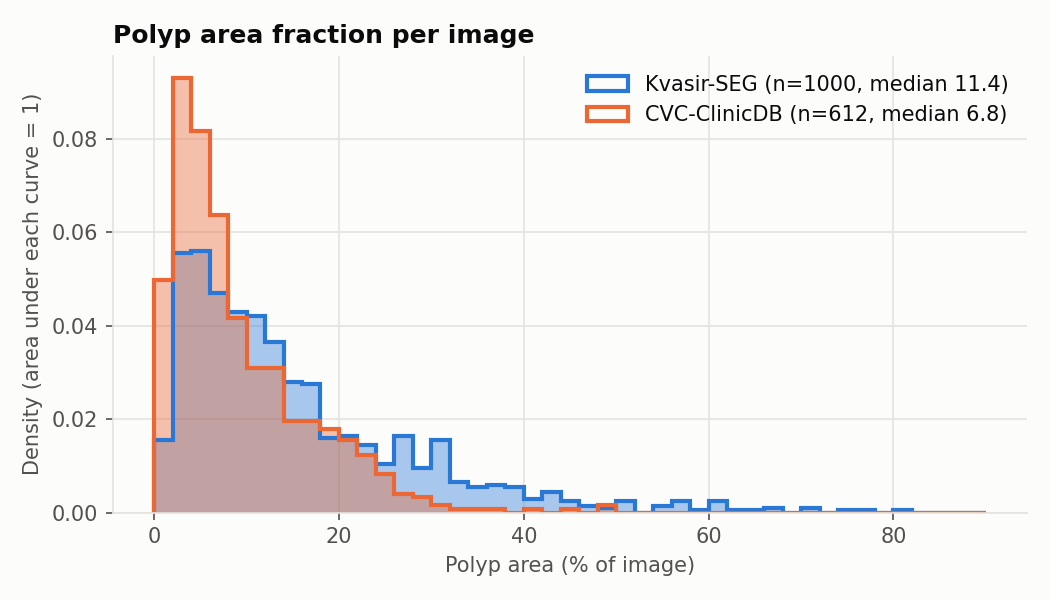

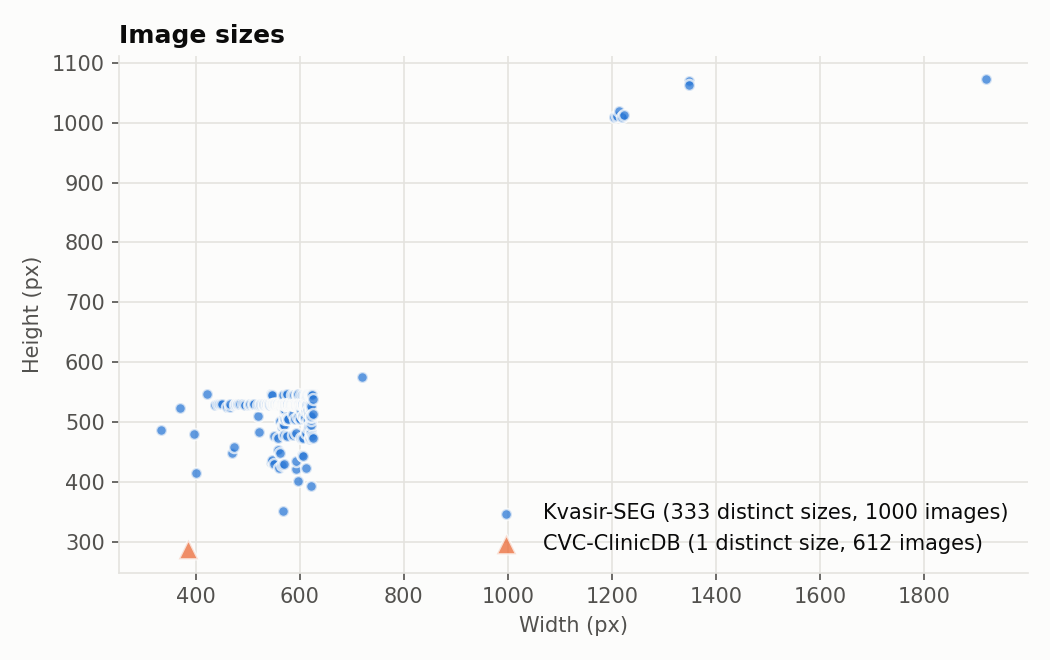

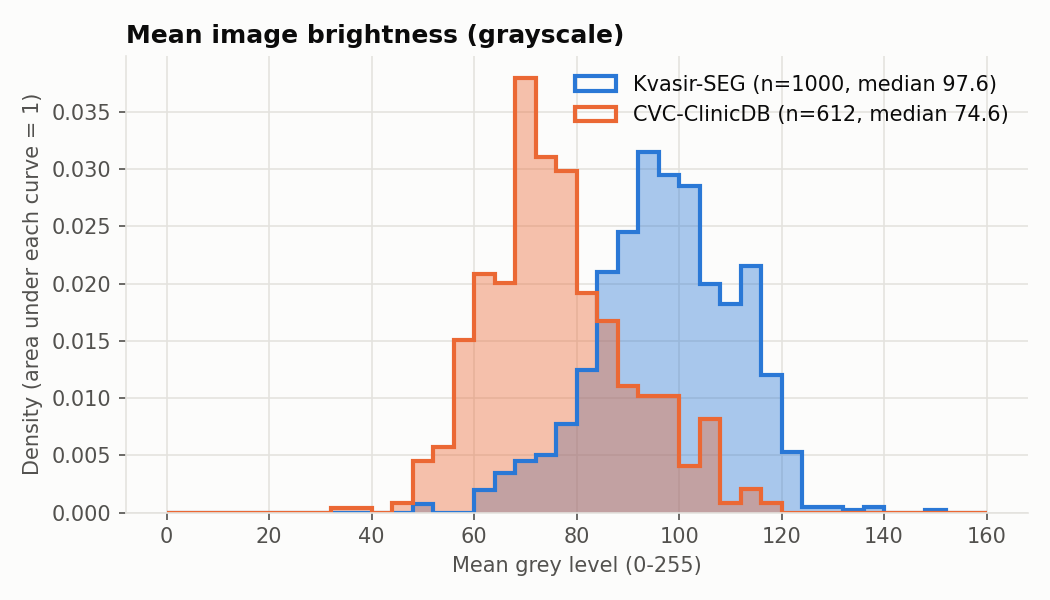

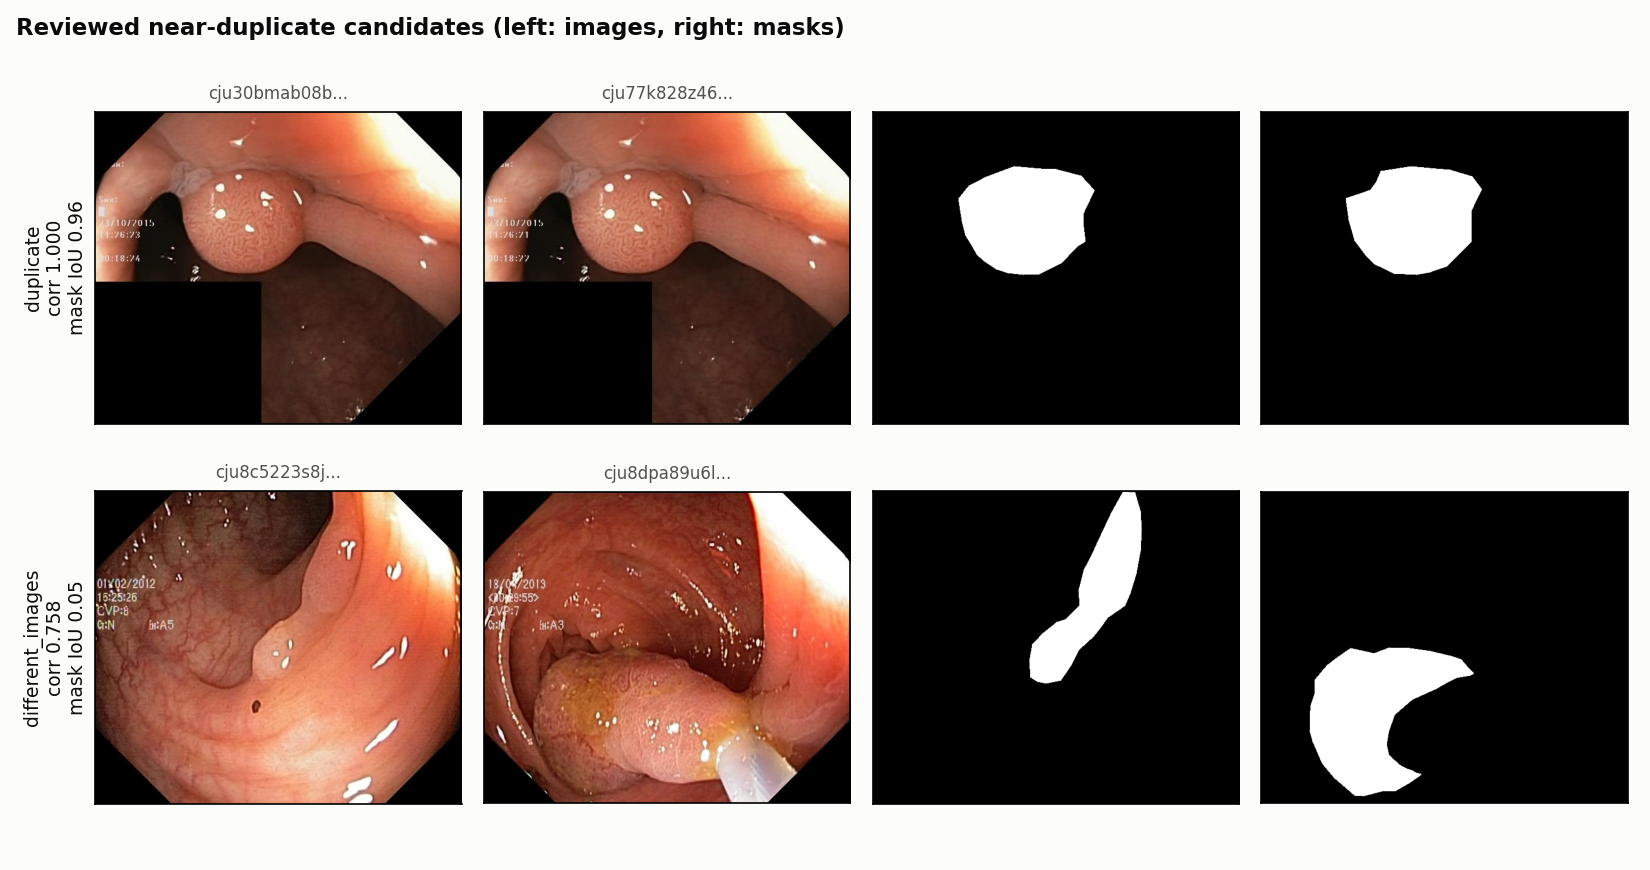

In [13]:
for name in ("fig_polyp_area_fraction.png", "fig_image_sizes.png", "fig_brightness_hist.png", "review_near_duplicates.png"):
    display(Image(filename=str(cfg.output_dir / name), width=640))

## 12. Reproducibility check
The whole audit is run a second time; every output file must be byte-identical.

In [14]:
import hashlib

def fingerprint(folder):
    return {p.relative_to(folder).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(folder.rglob("*")) if p.is_file()}

before = fingerprint(cfg.output_dir)
logging.getLogger("audit").setLevel(logging.WARNING)
write_outputs(run_audit(cfg, progress=False))
after = fingerprint(cfg.output_dir)
assert before == after, "outputs differ between runs"
print(f"Second run produced {len(after)} files, all byte-identical to the first run.")

Second run produced 18 files, all byte-identical to the first run.


## 13. Acceptance summary (plain English)

In [15]:
for r in ds.values():
    c = r.summary["counts"]
    print(f"- {r.cfg.name}: {c['matched_pairs']} image-mask pairs found (expected {c['expected_pairs']}); "
          f"{c['unmatched_images']} unmatched images, {c['unmatched_masks']} unmatched masks.")
print("\nProblems found:")
for p in result.problems:
    print(" *", p)
print("\nFlagged files (full list also in outputs/flagged_files.csv):")
display(result.flagged if len(result.flagged) else "No file was flagged (corrupt, empty, near-full, size mismatch, unmatched, exact duplicate or cross-dataset near-duplicate).")

- Kvasir-SEG: 1000 image-mask pairs found (expected 1000); 0 unmatched images, 0 unmatched masks.
- CVC-ClinicDB: 612 image-mask pairs found (expected 612); 0 unmatched images, 0 unmatched masks.

Problems found:
 * Kvasir-SEG: 1000 of 1000 masks contain values other than 0/255 (up to 18 distinct values in one mask; compression or anti-aliasing artefacts). They are binarised with > 127; 1000 of 1000 binarised masks have exactly two classes.
 * CVC-ClinicDB: 138 of 612 masks contain values other than 0/255 (up to 64 distinct values in one mask; compression or anti-aliasing artefacts). They are binarised with > 127; 612 of 612 binarised masks have exactly two classes.
 * CVC-ClinicDB: the sequence metadata lists 29 video sequences, but 31 were expected.
 * CVC-ClinicDB: the second (TIFF) copy of 612 images could not be decoded by Pillow, so the PNG/TIFF image cross-check was not possible (masks: 612/612 identical).
 * 183 near-duplicate image pair(s) within CVC-ClinicDB (pHash Hamming <=

'No file was flagged (corrupt, empty, near-full, size mismatch, unmatched, exact duplicate or cross-dataset near-duplicate).'

## 14. Full report
The generated `outputs/audit_report.md`, ready to copy into a methodology section.

In [16]:
display(Markdown((cfg.output_dir / "audit_report.md").read_text()))

# Dataset audit report

Seed 42; Python 3.9.6, numpy 1.26.4, pandas 2.3.3, scipy 1.13.1, Pillow 11.3.0, matplotlib 3.9.4. Masks are binarised with value > 127; a mask is 'near-full' above 90% polyp area; near-duplicates are images whose 64-bit perceptual hash differs in at most 4 bits.

## 1. Pair counts

| Dataset | Images | Masks | Matched pairs | Unmatched images | Unmatched masks | Expected | Status |
|---|---|---|---|---|---|---|---|
| Kvasir-SEG | 1000 | 1000 | 1000 | 0 | 0 | 1000 | OK |
| CVC-ClinicDB | 612 | 612 | 612 | 0 | 0 | 612 | OK |

- **Kvasir-SEG:** 1000 matched image-mask pairs were found, as expected (1000); no unmatched files.
- **CVC-ClinicDB:** 612 matched image-mask pairs were found, as expected (612); no unmatched files.

## 2. Problems found

- Kvasir-SEG: 1000 of 1000 masks contain values other than 0/255 (up to 18 distinct values in one mask; compression or anti-aliasing artefacts). They are binarised with > 127; 1000 of 1000 binarised masks have exactly two classes.
- CVC-ClinicDB: 138 of 612 masks contain values other than 0/255 (up to 64 distinct values in one mask; compression or anti-aliasing artefacts). They are binarised with > 127; 612 of 612 binarised masks have exactly two classes.
- CVC-ClinicDB: the sequence metadata lists 29 video sequences, but 31 were expected.
- CVC-ClinicDB: the second (TIFF) copy of 612 images could not be decoded by Pillow, so the PNG/TIFF image cross-check was not possible (masks: 612/612 identical).
- 183 near-duplicate image pair(s) within CVC-ClinicDB (pHash Hamming <= 4) (181 of them within the same video sequence).
- 7 near-duplicate image pair(s) within Kvasir-SEG (pHash Hamming <= 4).

## 3. Unreadable files

- **Kvasir-SEG:** all 1000 images and all masks opened and decoded completely.
- **CVC-ClinicDB:** all 612 images and all masks opened and decoded completely.

## 4. Image sizes

| Dataset | Distinct sizes | Width px | Height px | Channels | Image/mask size mismatches |
|---|---|---|---|---|---|
| Kvasir-SEG | 333 | 332-1920 (median 621) | 352-1072 (median 530) | 3 ch: 1000 | 0 |
| CVC-ClinicDB | 1 | 384-384 (median 384) | 288-288 (median 288) | 3 ch: 612 | 0 |

Most frequent sizes, Kvasir-SEG (full table: `image_sizes_kvasir.csv`):

| Width | Height | Channels | Images |
|---|---|---|---|
| 622 | 530 | 3 | 78 |
| 626 | 547 | 3 | 66 |
| 626 | 546 | 3 | 61 |
| 622 | 529 | 3 | 56 |
| 622 | 528 | 3 | 53 |
| 622 | 531 | 3 | 50 |
| 570 | 530 | 3 | 33 |
| 570 | 531 | 3 | 19 |
| 720 | 576 | 3 | 17 |
| 1348 | 1070 | 3 | 17 |

... and 323 more distinct sizes covering 550 images.

Most frequent sizes, CVC-ClinicDB (full table: `image_sizes_cvc.csv`):

| Width | Height | Channels | Images |
|---|---|---|---|
| 384 | 288 | 3 | 612 |

## 5. Mask values

| Dataset | Mask file mode | Masks with only {0,255} | Masks with other values | Max distinct values in one mask | Binarised: 2 classes | Binarised: 1 class |
|---|---|---|---|---|---|---|
| Kvasir-SEG | L: 1000 | 0 | 1000 | 18 | 1000 | 0 |
| CVC-ClinicDB | RGB: 612 | 474 | 138 | 64 | 612 | 0 |

Unique raw values of every mask are stored in the column `mask_unique_values` of the per-image CSV. Multi-channel masks are reduced to one channel with the maximum over channels before thresholding.

## 6. Empty and near-full masks

- **Kvasir-SEG:** 0 empty mask(s); 0 mask(s) covering > 90% of the image.
- **CVC-ClinicDB:** 0 empty mask(s); 0 mask(s) covering > 90% of the image.

## 7. Polyp area fraction and number of polyps

Area fraction = polyp pixels / all pixels of the binarised mask, in percent.

| Dataset | Mean | Median | Min | Q1 | Q3 | Max |
|---|---|---|---|---|---|---|
| Kvasir-SEG | 15.39 | 11.40 | 0.47 | 5.94 | 20.98 | 81.18 |
| CVC-ClinicDB | 9.17 | 6.83 | 0.34 | 3.63 | 12.73 | 48.96 |

| Dataset | Mean polyps | Median | Max | Masks with 1 | with 2 | with 3 | with 4+ |
|---|---|---|---|---|---|---|---|
| Kvasir-SEG | 1.21 | 1 | 10 | 819 | 164 | 14 | 3 |
| CVC-ClinicDB | 1.17 | 1 | 11 | 542 | 57 | 8 | 5 |

Polyps are counted as 4-connected components (`scipy.ndimage.label`) of the binarised mask. Small isolated specks left after thresholding noisy masks are counted too, so values above 1 can include annotation noise rather than separate polyps.

## 8. Brightness (for domain-shift analysis)

| Dataset | Grey mean | Grey std | Grey min | Grey max | R mean | G mean | B mean |
|---|---|---|---|---|---|---|---|
| Kvasir-SEG | 97.48 | 13.45 | 48.13 | 151.25 | 142.04 | 82.03 | 60.13 |
| CVC-ClinicDB | 76.19 | 13.86 | 35.70 | 119.96 | 102.21 | 68.70 | 46.95 |

On average Kvasir-SEG images are 21.3 grey levels brighter than CVC-ClinicDB images (97.5 vs 76.2 on a 0-255 scale).

## 9. Duplicates (report only; nothing was deleted)

Exact duplicates (identical file bytes): none, within or across the datasets.

Near-duplicates (perceptual hash, Hamming distance <= 4 of 64 bits). The threshold is deliberately strict; the table shows how many pairs exist at each distance.

| Scope | Hamming 0-1 | 2-3 | 4-5 | 6-7 | 8 | Near-duplicates (<= 4) |
|---|---|---|---|---|---|---|
| across datasets | 0 | 0 | 0 | 1 | 3 | 0 |
| within cvc | 14 | 43 | 126 | 313 | 685 | 183 |
| within kvasir | 3 | 1 | 3 | 22 | 149 | 7 |

**Across the two datasets:** 0 near-duplicate pair(s).

Closest cross-dataset pairs (all listed pairs are within 8 bits; full list in `duplicate_pairs.csv`):

| Image A | Image B | Hamming |
|---|---|---|
| kvasir/cju7d6ux323ze0987xos3srkx.jpg | cvc/576.png | 6 |
| kvasir/cju7flevb2wii08188otgs9p2.jpg | cvc/519.png | 8 |
| kvasir/ck2bxlujamu330725szlc2jdu.jpg | cvc/362.png | 8 |
| kvasir/ck2da7fwcjfis07218r1rvm95.jpg | cvc/193.png | 8 |

**Within CVC-ClinicDB:** 183 near-duplicate pair(s), 181 within the same video sequence.

| Image A | Image B | Hamming | Byte-identical |
|---|---|---|---|
| 2.png | 4.png | 0 | False |
| 48.png | 50.png | 0 | False |
| 62.png | 63.png | 0 | False |
| 112.png | 113.png | 0 | False |
| 194.png | 195.png | 0 | False |
| 194.png | 196.png | 0 | False |
| 195.png | 196.png | 0 | False |
| 198.png | 199.png | 0 | False |
| 200.png | 202.png | 0 | False |
| 220.png | 221.png | 0 | False |

... 173 more in `duplicate_pairs.csv`.

**Within Kvasir-SEG:** 7 near-duplicate pair(s).

| Image A | Image B | Hamming | Byte-identical |
|---|---|---|---|
| cju8amfdtqi4x09871tygrgqe.jpg | cju886ryxnsl50801r93jai7q.jpg | 0 | False |
| cju30bmab08bi0835mvlr6e0r.jpg | cju77k828z46w0871r0avuoo9.jpg | 0 | False |
| cju76lsehyia10987u54vn8rb.jpg | cju772304yw5t0818vbw8kkjf.jpg | 0 | False |
| cju8c5223s8j80850b4kealt4.jpg | cju8dpa89u6l80818dj6lldh9.jpg | 2 | False |
| cju7cue9b232j0801qdzk1ykj.jpg | cju7fob3x301u0755x985pmmq.jpg | 4 | False |
| cju8c1a0ws7o208181c6lbsom.jpg | cju13cgqmnhwn0988yrainhcp.jpg | 4 | False |
| cju8c1a0ws7o208181c6lbsom.jpg | cju83kxitjv340987z09m0ezy.jpg | 4 | False |

- Leakage check, Kvasir-SEG: 1 of 7 within-dataset near-duplicate pairs lie in different splits; 1 of these were reviewed by hand as different images (pHash false positives), so 0 remain as possible leakage.
- Leakage check, CVC-ClinicDB: 0 of 183 within-dataset near-duplicate pairs lie in different splits; 0 of these were reviewed by hand as different images (pHash false positives), so 0 remain as possible leakage.

Near-duplicate candidates reviewed by hand (figure: `review_near_duplicates.png`). Verdict `duplicate` = the pair is forced into one split; `different_images` = pHash false positive, no action.

| Dataset | Image A | Image B | Image correlation | Mask IoU | Verdict | Note |
|---|---|---|---|---|---|---|
| Kvasir-SEG | cju30bmab08bi0835mvlr6e0r | cju77k828z46w0871r0avuoo9 | 0.9998 | 0.96 | duplicate | adjacent frames of the same polyp (same overlay timestamp, 2 s apart); image correlation 0.9997, mask IoU 0.95 |
| Kvasir-SEG | cju8c5223s8j80850b4kealt4 | cju8dpa89u6l80818dj6lldh9 | 0.7575 | 0.05 | different_images | pHash false positive caused by the shared black octagonal border; different patients and polyps (2012 vs 2013), image correlation 0.75, mask IoU 0.05 |

## 10. Fixed splits

| Dataset | Method | Seed | Train/val/test pairs | Sequences | Approximation |
|---|---|---|---|---|---|
| Kvasir-SEG | random | 42 | 800/100/100 | n/a | no |
| CVC-ClinicDB | sequence_grouped | 42 | 429/92/91 | 29 | no |

- **Kvasir-SEG:** Random permutation of the sorted file stems with numpy default_rng(seed); manually confirmed near-duplicate pairs are kept in the same split.
- **CVC-ClinicDB:** Whole video sequences are assigned to one split (seeded shuffle, largest first, greedy balancing). Fractions are matched as closely as whole sequences allow. Achieved fractions: {'train': 0.701, 'val': 0.1503, 'test': 0.1487} (target {'train': 0.7, 'val': 0.15, 'test': 0.15}).

Each split is checked by assertion: the parts are disjoint, together cover every usable pair exactly once, and (sequence split) no sequence appears in two parts. Every dataset's complete pair list is also saved as an external-test list (`splits/*_external_test.json`). Files: `outputs/splits/`.

- Sequence information for CVC-ClinicDB (read from 'metadata.csv'): 29 sequences, 6-26 frames each (median 22).

## 11. Second image copy cross-check (CVC-ClinicDB)

Masks: 612 of 612 compared mask pairs are pixel-identical between the main copy and the second copy. Images: the second copy of 612 of 612 images could not be decoded by Pillow, so images were NOT compared.

## 12. Flagged files

Flag meanings: `corrupt_*` cannot be fully decoded; `size_mismatch` image and mask sizes differ; `empty_mask` no polyp pixel after binarising; `near_full_mask` more than 90% polyp; `not_two_class` binarised mask does not have two classes; `unmatched_*` no partner file; `exact_duplicate`; `near_duplicate_across_datasets`. Within-dataset near-duplicates and noisy-but-valid masks are not listed per file (see sections 5 and 9, `duplicate_pairs.csv`).

No file was flagged.

